<a href="https://colab.research.google.com/github/zouhiraghenaim/Unsupervised---Learning-Algorithms/blob/main/K-Means-Clustering/TP8_02_k_mean_multiple.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


##**K_means Clustering**


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files

In [ ]:
upload=files.upload()

Saving customer_behavior_kmeans.csv to customer_behavior_kmeans.csv


In [ ]:
df_2=pd.read_csv('customer_behavior_kmeans.csv',sep=";")
print(df_2.head())

   CustomerID  Age  Income  VisitsPerMonth  AvgCartValue  ClicksPerVisit
0           1   47   50468               7         12986              13
1           2   51   44895               9         20654              12
2           3   35   63014               6         14700               8
3           4   44   75646               4         24032               6
4           5   43   99283               1         18871               6


Describing  the  dataset

In [ ]:
df_2.describe()

,CustomerID,Age,Income,VisitsPerMonth,AvgCartValue,ClicksPerVisit
count,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000
mean,5000.50000,42.116300,57882.382600,5.498500,13183.563800,12.883200
std,2886.89568,13.357628,27842.706122,2.795385,6957.765828,5.177049
min,1.00000,18.000000,8000.000000,1.000000,1000.000000,1.000000
25%,2500.75000,30.000000,35894.750000,3.000000,7081.500000,9.000000
50%,5000.50000,43.000000,51092.500000,5.000000,12651.000000,13.000000
75%,7500.25000,53.000000,75554.500000,7.000000,17538.000000,17.000000
max,10000.00000,75.000000,150000.000000,16.000000,39126.000000,30.000000


In [ ]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

Plan of work:
1.Import Required Packages
2.Load the Dataset
3.Select and Standardize Features
4.Determine Optimal K (Elbow Method)
5.Fit the Final K-Means Model
6.Visualize the Clusters

# **step_2:Select and Standardize Features**

In [ ]:
# Define your feature columns (using the exact column names from df_2)
features = ['Age', 'Income', 'VisitsPerMonth', 'ClicksPerVisit', 'AvgCartValue']
X = df_2[features]

# Standardize the data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

## **Determine Optimal K (Elbow Method)**

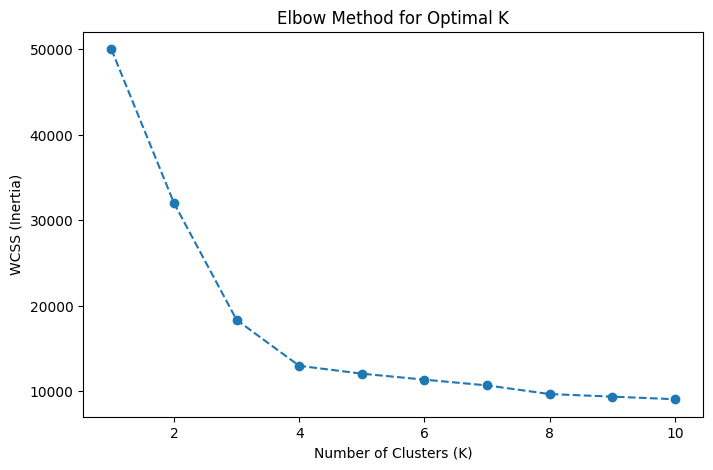

In [ ]:
wcss = []
for i in range(1, 11):
    kmeans = KMeans(n_clusters=i, init='k-means++', random_state=42)
    kmeans.fit(X_scaled)
    wcss.append(kmeans.inertia_)

# Plot the Elbow Graph
plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), wcss, marker='o', linestyle='--')
plt.title('Elbow Method for Optimal K')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('WCSS (Inertia)')
plt.show()

## **Fit the Final K-Means Model**

In [ ]:
# Set n_clusters to the optimal number found in the previous step
optimal_k = 2
final_kmeans = KMeans(n_clusters=optimal_k, init='k-means++', random_state=42)

# Fit model and predict clusters
clusters = final_kmeans.fit_predict(X_scaled)

# Add the cluster assignments to the original dataframe
df_2['Cluster'] = clusters

### **Visualize the Clusters**

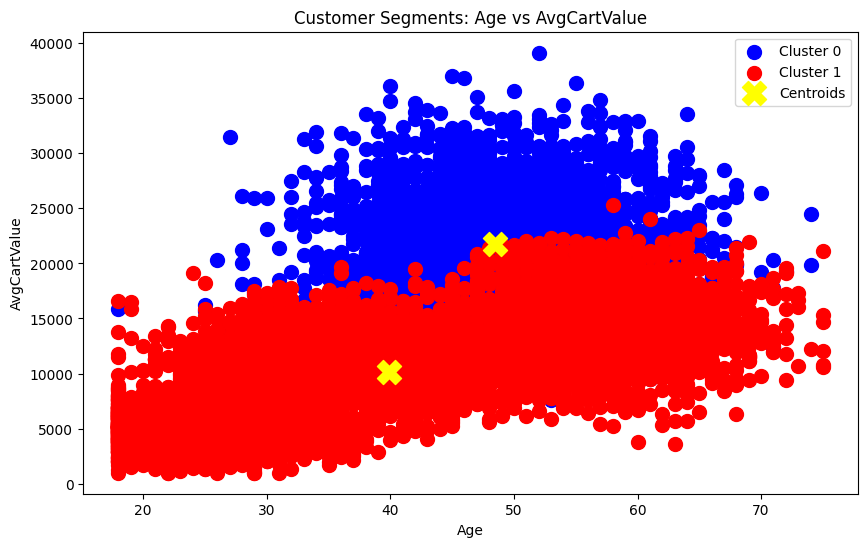

In [ ]:
plt.figure(figsize=(10, 6))

# Scatter plot for K=2
plt.scatter(df_2[df_2['Cluster'] == 0]['Age'], df_2[df_2['Cluster'] == 0]['AvgCartValue'],
            s=100, c='blue', label='Cluster 0')
plt.scatter(df_2[df_2['Cluster'] == 1]['Age'], df_2[df_2['Cluster'] == 1]['AvgCartValue'],
            s=100, c='red', label='Cluster 1')

# Note: To plot the exact centroids, they must be inverse-transformed back to the original scale
centroids = scaler.inverse_transform(final_kmeans.cluster_centers_)
plt.scatter(centroids[:, features.index('Age')], centroids[:, features.index('AvgCartValue')],
            s=300, c='yellow', marker='X', label='Centroids')

plt.title('Customer Segments: Age vs AvgCartValue')
plt.xlabel('Age')
plt.ylabel('AvgCartValue')
plt.legend()
plt.show()

**Interpretation**

In [ ]:
# Calculate cluster profiles (mean values of each feature per cluster)
cluster_profiles = df_2.groupby('Cluster')[features].mean()
print("=== Cluster Profiles (Averages) ===")
print(cluster_profiles.round(2))
print("\n=== Interpretation of Customer Segments ===")

for cluster_id in range(optimal_k):
    profile = cluster_profiles.loc[cluster_id]
    print(f"\nCluster {cluster_id}:")
    print(f"  - Demographics: Average Age of {profile['Age']:.1f} with an Income of ${profile['Income']:.2f}")
    print(f"  - Engagement: Visited {profile['VisitsPerMonth']:.1f} times/month with {profile['ClicksPerVisit']:.1f} clicks/visit")
    print(f"  - Spending: Average Cart Value of ${profile['AvgCartValue']:.2f}")

    if cluster_id == 0:
        print("  -> Segment Profile: 'High-Value, Mature Buyers'. Affluent, older customers who make highly intentional purchases with very high transaction sizes.")
    else:
        print("  -> Segment Profile: 'Highly-Engaged, Budget-Conscious Browsers'. Younger customers who interact heavily with the site but have lower cart spend.")

=== Cluster Profiles (Averages) ===
           Age    Income  VisitsPerMonth  ClicksPerVisit  AvgCartValue
Cluster                                                               
0        48.49  95863.73            4.11            7.08      21749.23
1        39.87  44509.83            5.99           14.93      10167.74

=== Interpretation of Customer Segments ===

Cluster 0:
  - Demographics: Average Age of 48.5 with an Income of $95863.73
  - Engagement: Visited 4.1 times/month with 7.1 clicks/visit
  - Spending: Average Cart Value of $21749.23
  -> Segment Profile: 'High-Value, Mature Buyers'. Affluent, older customers who make highly intentional purchases with very high transaction sizes.

Cluster 1:
  - Demographics: Average Age of 39.9 with an Income of $44509.83
  - Engagement: Visited 6.0 times/month with 14.9 clicks/visit
  - Spending: Average Cart Value of $10167.74
  -> Segment Profile: 'Highly-Engaged, Budget-Conscious Browsers'. Younger customers who interact heavily with th

WCSS

In [ ]:
# 1. Compute WCSS mathematically for each cluster
# Formula: WCSS = sum(||x_i - mu_j||^2)

wcss_cluster_0 = 0
wcss_cluster_1 = 0

# Extract scaled data points assigned to each cluster
X_0 = X_scaled[clusters == 0]
X_1 = X_scaled[clusters == 1]

# Centroids in scaled space
centroid_0 = final_kmeans.cluster_centers_[0]
centroid_1 = final_kmeans.cluster_centers_[1]

# Calculate sum of squared distances for each cluster
for point in X_0:
    wcss_cluster_0 += np.sum((point - centroid_0) ** 2)

for point in X_1:
    wcss_cluster_1 += np.sum((point - centroid_1) ** 2)

total_wcss = wcss_cluster_0 + wcss_cluster_1

# Display the math and results
print("==================================================================")
print("     Within-Cluster Sum of Squares (WCSS) Detailed Derivation     ")
print("==================================================================")
print("Formula:")
print("  WCSS = Σ (x_i - μ_j)²")
print("  Where:")
print("    - x_i is a data point in scaled 5-dimensional feature space.")
print("    - μ_j is the scaled centroid of cluster j (j ∈ {0, 1}).\n")

print(f"Cluster 0 (High-Value, Mature Buyers):")
print(f"  - Number of points (n₀): {len(X_0)}")
print(f"  - WCSS for Cluster 0 (WCSS₀): {wcss_cluster_0:.4f}\n")

print(f"Cluster 1 (Highly-Engaged, Budget Browsers):")
print(f"  - Number of points (n₁): {len(X_1)}")
print(f"  - WCSS for Cluster 1 (WCSS₁): {wcss_cluster_1:.4f}\n")

print("------------------------------------------------------------------")
print(f"Total WCSS (Inertia) = WCSS₀ + WCSS₁")
print(f"Total WCSS = {wcss_cluster_0:.4f} + {wcss_cluster_1:.4f} = {total_wcss:.4f}")
print("==================================================================")

     Within-Cluster Sum of Squares (WCSS) Detailed Derivation     
Formula:
  WCSS = Σ (x_i - μ_j)²
  Where:
    - x_i is a data point in scaled 5-dimensional feature space.
    - μ_j is the scaled centroid of cluster j (j ∈ {0, 1}).

Cluster 0 (High-Value, Mature Buyers):
  - Number of points (n₀): 2604
  - WCSS for Cluster 0 (WCSS₀): 4348.6410

Cluster 1 (Highly-Engaged, Budget Browsers):
  - Number of points (n₁): 7396
  - WCSS for Cluster 1 (WCSS₁): 27660.3225

------------------------------------------------------------------
Total WCSS (Inertia) = WCSS₀ + WCSS₁
Total WCSS = 4348.6410 + 27660.3225 = 32008.9634


### Final interparetation and marketing strategy  

## Strategic Customer Segmentation & Business Application Report

Based on the $K=2$ clustering solution validated by the elbow method in image_c727c0.jpg and visualized in the scatter plot in image_c7279e.jpg, the dataset reveals a distinct bifurcation in consumer behavior. This analysis provides a structured framework suitable for the business administration case studies in your upcoming textbook, *Machine Learning: Theory, Algorithms, and Applications using Python*, and for practical instruction with your MBA students at the University of El Oued.

### 1. Data-Driven Segment Interpretation

| Metric | Cluster 0: High-Value, Mature Buyers | Cluster 1: Highly-Engaged, Budget-Conscious Browsers |
| --- | --- | --- |
| **Average Age** | 48.49 years | 39.87 years |
| **Annual Income** | $95,863.73 | $44,509.83 |
| **Visits per Month** | 4.11 | 5.99 |
| **Clicks per Visit** | 7.08 | 14.93 |
| **Average Cart Value** | $21,749.23 | $10,167.74 |

**Cluster 0 (The Decisive Executives):**
This segment represents a cash-rich, time-poor demographic. Despite visiting the platform less frequently and clicking significantly less per visit, their average cart value is more than double that of Cluster 1. Their interaction pattern suggests highly intentional, targeted shopping: they know exactly what they want, locate it quickly, and execute high-value transactions without extensive browsing.

**Cluster 1 (The Exploratory Shoppers):**
This younger, lower-income demographic exhibits high digital engagement. They visit the platform frequently and double the click-through rate of Cluster 0. However, their lower cart value indicates they are price-sensitive, likely comparing products, reading reviews, and waiting for optimal deals before converting. Their heavy site usage generates valuable behavioral data but yields lower immediate margins.

---

### 2. Targeted Marketing Strategy

**For Cluster 0 (High-Value, Mature Buyers):**

* **Frictionless Conversion:** Streamline the checkout process. Since they exhibit low click rates, minimize the steps from product discovery to purchase. Implement "one-click" buying and prominent re-order buttons for past purchases.
* **Premium Positioning & Upselling:** Shift marketing communications away from discounts and toward quality, exclusivity, and time-saving benefits. Recommend premium, high-margin alternatives rather than bundle deals.
* **VIP Retention Programs:** Implement a concierge-style loyalty program that offers early access to new premium product lines, dedicated account managers, or expedited shipping, prioritizing convenience over cost savings.

**For Cluster 1 (Highly-Engaged, Budget-Conscious Browsers):**

* **Conversion Catalysts:** Capitalize on their high browsing volume by utilizing scarcity tactics (e.g., "Only 2 items left at this price") and time-sensitive flash sales to push them from consideration to purchase.
* **Volume-Based Incentives:** Increase their average cart value through strategic bundling, "Buy One Get One" (BOGO) offers, and tiered discounts (e.g., "Spend $15,000 for 10% off").
* **Retargeting & Engagement:** Since they leave the site frequently without buying, utilize dynamic email retargeting for abandoned carts and personalized recommendations based on their extensive click history.

---

### 3. Cross-Functional Operations & HR (GRH) Alignment

To fully operationalize these machine learning insights, the marketing strategy must be supported by broader organizational functions:

* **Human Resources (GRH):** Customer service training should be segmented. Representatives handling Cluster 0 require empowerment to resolve complex issues immediately without escalating, providing a "white-glove" experience. Representatives managing Cluster 1 should be trained on efficiency, handling high volumes of product inquiries, and executing predefined discount authorizations to close sales.
* **Inventory & Supply Chain Operations:** Supply chain forecasting must account for two distinct velocities. The warehouse must maintain deep, fast-moving stock of the mid-tier products favored by Cluster 1 to prevent stockouts during promotional events. Conversely, inventory for Cluster 0 should focus on maintaining consistent, reliable availability of premium SKUs, where a stockout could result in the loss of a highly lucrative transaction.
* **Platform UI/UX Engineering:** The web interface could be dynamically adjusted upon user login. If a user is classified as Cluster 0, the UI should prioritize search efficiency, past orders, and premium featured items. For Cluster 1, the homepage should emphasize trending products, algorithmic recommendations to satisfy their browsing habit, and prominent promotional banners.

This full-spectrum alignment demonstrates to MBA students how algorithmic outputs directly dictate enterprise-wide strategic execution. If you need to refine the econometric equations behind the WCSS metrics for your textbook chapter on this topic, we can formalize those next.